# Regional Labor Market Resilience — Descriptive Baseline and Stage 1 Counterfactual Forecasts

The panel spans **January 2010–December 2023**. The no-pandemic forecasting sample ends **February 2020**. The 46-month forecast period runs **March 2020–December 2023**. Observed pandemic-period outcomes are **never used to fit, tune, or select** the counterfactual models.


## 0. Dependencies and configuration
Run this notebook from a VS Code Jupyter kernel with `pandas`, `numpy`, `matplotlib`, `scikit-learn`, `statsmodels`, and `openpyxl` installed. ETS and SARIMA are **optional**, disabled by default because fitting both to hundreds of CBSAs can take considerable time.

In [1]:
# %pip install pandas numpy matplotlib scikit-learn statsmodels openpyxl joblib threadpoolctl

from pathlib import Path
import json, sys, warnings, platform
import os
from joblib import Parallel, delayed
from threadpoolctl import threadpool_limits
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

SEED = 2026
np.random.seed(SEED)

# Detect repo root whether notebook is launched from repo root or code/.
candidates = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
ROOT = next((p for p in candidates if (p / 'data' / 'processed' / 'qcew_cbsa_monthly_2010_2023.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Could not find data/processed/qcew_cbsa_monthly_2010_2023.csv. Open the notebook in the cloned repository and check the working directory.')
CODE = ROOT / 'code'
PROCESSED = ROOT / 'data' / 'processed'
OUTPUT = ROOT / 'output'
OUTPUT.mkdir(parents=True, exist_ok=True)

# Reproducible defaults. Switch optional models on only after checking baselines.
RUN_ETS = True
RUN_SARIMA = True
MAX_CBSAS = None  # None means all; use 10 for a quick smoke test.
# 24 logical cores / 32 GB RAM: begin with 12 processes to avoid memory pressure.
# Benchmark 8, 12, 16 workers before attempting 20 or more.
N_JOBS = min(12, max(1, (os.cpu_count() or 2) - 2))
PARALLEL_BACKEND = 'loky'
FORECAST_END = '2023-12-01'
TRAIN_END = '2020-02-01'
VALIDATION_ORIGINS = ['2016-12-01', '2017-12-01', '2018-12-01']
VALIDATION_HORIZON = 12

print('Repository:', ROOT)
print('Python:', sys.version.split()[0])
print('Pandas:', pd.__version__)
print('Output:', OUTPUT)

print('Logical CPU cores:', os.cpu_count(), '| Joblib workers:', N_JOBS)


Repository: c:\Users\adamt\OneDrive\Documents\Directed Practicum\regional-labor-resilience
Python: 3.12.10
Pandas: 3.0.6
Output: c:\Users\adamt\OneDrive\Documents\Directed Practicum\regional-labor-resilience\output
Logical CPU cores: 24 | Joblib workers: 12


## 1. Load and audit the provisional CBSA panel
The input is expected to contain `cbsa_code`, `date`, `employment`, and `cbsa_type`. Missing employment, duplicate CBSA-months, and nonpositive levels are treated as data-quality errors rather than silently imputed.

In [2]:
source_file = PROCESSED / 'qcew_cbsa_monthly_2010_2023.csv'
panel = pd.read_csv(source_file, dtype={'cbsa_code': 'string'})
required = {'cbsa_code', 'date', 'employment', 'cbsa_type'}
assert required.issubset(panel.columns), f'Missing columns: {required - set(panel.columns)}'
panel['cbsa_code'] = panel['cbsa_code'].str.zfill(5)
panel['date'] = pd.to_datetime(panel['date'])
panel['employment'] = pd.to_numeric(panel['employment'], errors='coerce')
panel = panel.sort_values(['cbsa_code', 'date']).reset_index(drop=True)
assert not panel.duplicated(['cbsa_code', 'date']).any(), 'Duplicate CBSA-month rows'
assert panel['employment'].notna().all(), 'Missing employment: investigate before forecasting'
assert (panel['employment'] > 0).all(), 'Nonpositive employment: investigate'
assert panel['cbsa_type'].notna().all(), 'Missing CBSA type'
assert panel['date'].min() == pd.Timestamp('2010-01-01')
assert panel['date'].max() == pd.Timestamp('2023-12-01')
expected_dates = pd.date_range('2010-01-01', '2023-12-01', freq='MS')
assert panel.groupby('cbsa_code').size().eq(len(expected_dates)).all()
assert panel['cbsa_code'].nunique() == 926, 'Sample differs from the provisional 926-CBSA audit; review before proceeding'
print('CBSAs:', panel.cbsa_code.nunique(), '| CBSA-months:', len(panel))
print('Metro/micro:', panel[['cbsa_code','cbsa_type']].drop_duplicates()['cbsa_type'].value_counts().to_dict())
display(panel.head())


CBSAs: 926 | CBSA-months: 155568
Metro/micro: {'Micropolitan Statistical Area': 539, 'Metropolitan Statistical Area': 387}


,cbsa_code,date,employment,cbsa_type,period
0,10100,2010-01-01,20377.0,Micropolitan Statistical Area,pre_pandemic
1,10100,2010-02-01,20421.0,Micropolitan Statistical Area,pre_pandemic
2,10100,2010-03-01,20644.0,Micropolitan Statistical Area,pre_pandemic
3,10100,2010-04-01,21071.0,Micropolitan Statistical Area,pre_pandemic
4,10100,2010-05-01,21462.0,Micropolitan Statistical Area,pre_pandemic


## 2. Descriptive sample audit and employment distributions

In [3]:
panel['employment_growth_yoy'] = panel.groupby('cbsa_code')['employment'].pct_change(12, fill_method=None)
summary = panel.groupby('cbsa_type').agg(
    cbsa_months=('employment','size'),
    median_employment=('employment','median'),
    mean_employment=('employment','mean'),
    min_employment=('employment','min'),
    max_employment=('employment','max')
).reset_index()
summary['cbsa_count'] = summary['cbsa_type'].map(panel.groupby('cbsa_type')['cbsa_code'].nunique())
summary.to_csv(OUTPUT / 'table_descriptive_employment_by_type.csv', index=False)
display(summary)

extreme = panel.loc[panel['employment_growth_yoy'].abs() > .5,
                    ['cbsa_code','date','employment','employment_growth_yoy','cbsa_type']]
extreme.to_csv(OUTPUT / 'flagged_yoy_growth_over_50pct.csv', index=False)
print('Flagged >50% absolute YoY changes:', len(extreme))
display(extreme.head(25))


,cbsa_type,cbsa_months,median_employment,mean_employment,min_employment,max_employment,cbsa_count
0,Metropolitan Statistical Area,65016,97575.0,310924.503199,12725.0,9454987.0,387
1,Micropolitan Statistical Area,90552,16487.0,19196.045664,2574.0,100984.0,539


Flagged >50% absolute YoY changes: 15


,cbsa_code,date,employment,employment_growth_yoy,cbsa_type
18951,14720,2021-04-01,24229.0,0.565484,Micropolitan Statistical Area
43311,21140,2021-04-01,134834.0,0.561302,Metropolitan Statistical Area
98751,34880,2021-04-01,6380.0,0.609079,Micropolitan Statistical Area
102951,36180,2021-04-01,22993.0,0.507441,Micropolitan Statistical Area
151722,48780,2011-07-01,24078.0,0.501590,Micropolitan Statistical Area
151724,48780,2011-09-01,25792.0,0.508304,Micropolitan Statistical Area
151725,48780,2011-10-01,26539.0,0.501160,Micropolitan Statistical Area
151726,48780,2011-11-01,27932.0,0.554541,Micropolitan Statistical Area
151727,48780,2011-12-01,29135.0,0.563875,Micropolitan Statistical Area
151728,48780,2012-01-01,29833.0,0.524659,Micropolitan Statistical Area


## 3. Descriptive employment indices
Each aggregate series is indexed to **February 2020 = 100** for visualization only. The index is *not* the no-pandemic counterfactual.

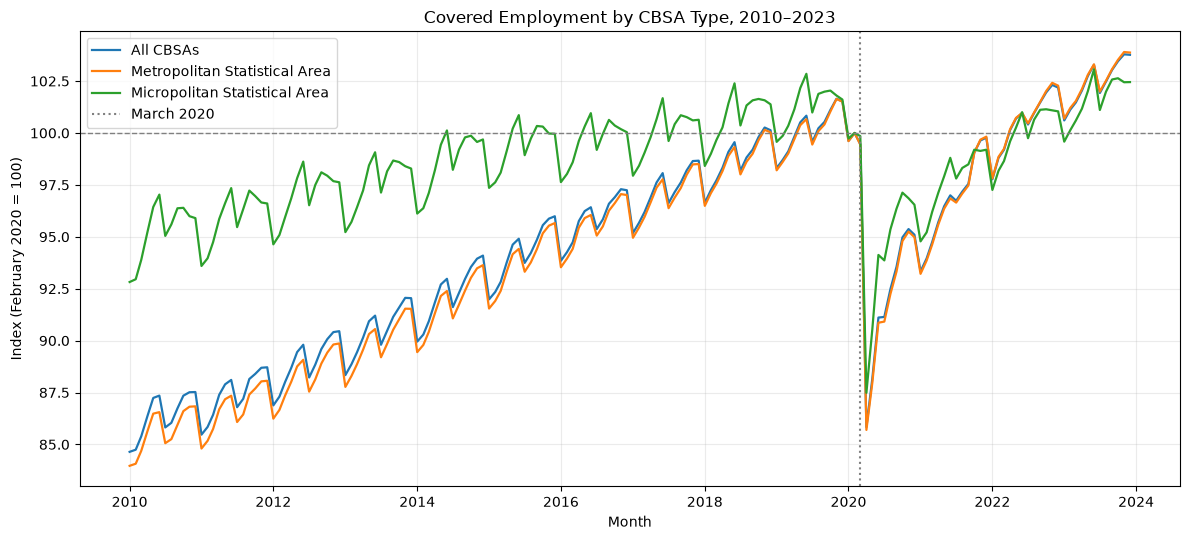

In [4]:
by_type = panel.groupby(['date','cbsa_type'], as_index=False)['employment'].sum()
all_cbsa = panel.groupby('date', as_index=False)['employment'].sum()
all_cbsa['cbsa_type'] = 'All CBSAs'
indices = pd.concat([by_type, all_cbsa], ignore_index=True)
base = indices.loc[indices.date.eq(pd.Timestamp('2020-02-01')), ['cbsa_type','employment']].rename(columns={'employment':'base_employment'})
indices = indices.merge(base, on='cbsa_type', validate='many_to_one')
indices['employment_index'] = 100 * indices.employment / indices.base_employment
indices.to_csv(OUTPUT / 'descriptive_employment_indices_2010_2023.csv', index=False)
fig, ax = plt.subplots(figsize=(12, 5.5))
for group, data in indices.groupby('cbsa_type'):
    ax.plot(data.date, data.employment_index, label=group, linewidth=1.6)
ax.axhline(100, color='gray', linestyle='--', linewidth=1)
ax.axvline(pd.Timestamp('2020-03-01'), color='gray', linestyle=':', linewidth=1.5, label='March 2020')
ax.set(title='Covered Employment by CBSA Type, 2010–2023', xlabel='Month', ylabel='Index (February 2020 = 100)')
ax.legend(); ax.grid(alpha=.25); fig.tight_layout()
fig.savefig(OUTPUT / 'figure_employment_index_by_cbsa_type.png', dpi=300, bbox_inches='tight')
plt.show()


## 4. Forecasting models and pre-pandemic rolling-origin evaluation

**Stage 1 target:** monthly QCEW employment for each CBSA. All forecasts are generated from the data available at each training cutoff. The four candidate specifications are:

1. **Seasonal naive:** repeat employment from the same month of the previous year (recursively for longer horizons).
2. **Seasonal naive + drift:** seasonal naive with an annualized change estimated from the first and last complete years of the training sample. This is a simple sensitivity benchmark.
3. **Trend + monthly fixed effects:** linear regression of log employment on a time trend and 11 month indicators, extrapolated to the forecast horizon.
4. **ETS / SARIMA (optional):** fitted separately for each CBSA and origin; can be disabled for runtime

Model selection minimizes **mean pre-pandemic validation MAE divided by the CBSA's training-period mean employment**, averaged over origins. This scale normalization prevents large CBSAs from dominating selection. Raw MAE and RMSE are also reported. Three annual origins yield twelve-month validation forecasts entirely before March 2020. They **do not establish accuracy at the 46-month pandemic horizon**.

In [5]:
def seasonal_naive(y, horizon):
    y = np.asarray(y, dtype=float)
    if len(y) < 12: raise ValueError('Need at least 12 months')
    return np.resize(y[-12:], horizon)

def seasonal_drift(y, horizon):
    y = np.asarray(y, dtype=float)
    if len(y) < 24: raise ValueError('Need at least 24 months')
    # Estimate annual change from first and last 12-month blocks.
    annual_steps = (len(y) - 12) / 12
    annual_change = (y[-12:].mean() - y[:12].mean()) / annual_steps
    return np.maximum(1, seasonal_naive(y, horizon) + annual_change * (np.arange(horizon) // 12 + 1))

def trend_seasonal(y, horizon):
    y = np.asarray(y, dtype=float)
    if np.any(y <= 0): raise ValueError('Trend-seasonal requires positive levels')
    n = len(y)
    t = np.arange(n)
    # Month indices are relative to series start; input is complete and starts Jan 2010.
    months = t % 12
    X = np.column_stack([t, pd.get_dummies(months).reindex(columns=range(1,12), fill_value=False).astype(float).to_numpy()])
    future_t = np.arange(n, n + horizon)
    future_months = future_t % 12
    X_future = np.column_stack([future_t, pd.get_dummies(future_months).reindex(columns=range(1,12), fill_value=False).astype(float).to_numpy()])
    fit = LinearRegression().fit(X, np.log(y))
    return np.exp(np.clip(fit.predict(X_future), -20, 25))

# Expanded diagnostic/model-selection routines are defined in the next cell.
# Baselines remain unchanged. ETS and SARIMA are selected within each
# pre-pandemic training window, with no post-February-2020 information.
MODELS = {'seasonal_naive': seasonal_naive,
          'seasonal_drift': seasonal_drift,
          'trend_seasonal': trend_seasonal}


### 4A. ETS/SARIMA candidate identification and diagnostics

**Implementation:** For each training origin, fit a small, pre-specified set of ETS and SARIMA candidates. Select the lowest-AICc converged candidate *within each family*, then compare those family representatives with the existing baselines using rolling-origin forecast errors. This avoids leaking the validation outcomes into specification selection. The chosen family is re-identified and refit using data through February 2020 for the 46-month counterfactual. AICc is used only within a model family; rolling validation selects across families. Residual Ljung–Box results and forecast plausibility are audited, not treated as automatic significance-based exclusions. SARIMA fits use a log employment scale and enforced stability/invertibility; exponentiated point forecasts are median-scale estimates without lognormal bias correction. No forecast values are clipped to hide instability.

The candidate set is intentionally limited for a workstation run. Increase it only after examining diagnostic plots. Long-horizon forecasts require additional sensitivity validation; 12-month CV alone cannot validate a 46-month counterfactual.
All parameter searches occur separately for each CBSA **within each pre-pandemic training origin**. AICc ranks candidates *within* ETS and SARIMA; rolling-origin normalized MAE selects the model family. Candidate lists are deliberately bounded for tractability; they are not an exhaustive automatic order search.


In [6]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss

DIAG_OUTPUT = OUTPUT / 'stage1_diagnostics'
DIAG_OUTPUT.mkdir(parents=True, exist_ok=True)

ETS_CANDIDATES = {
    'additive_no_trend': dict(trend=None, seasonal='add', damped_trend=False),
    'additive_trend': dict(trend='add', seasonal='add', damped_trend=False),
    'additive_damped': dict(trend='add', seasonal='add', damped_trend=True),
    'multiplicative_seasonal_damped': dict(trend='add', seasonal='mul', damped_trend=True),
    'multiplicative_seasonal_trend': dict(trend='add', seasonal='mul', damped_trend=False),
}
# Restricted set for tractability; D=0 and D=1 both represented.
SARIMA_CANDIDATES = [
    ((0,1,1),(0,1,1,12)),
    ((1,1,0),(0,1,1,12)),
    ((1,1,1),(0,1,1,12)),
    ((1,1,1),(1,0,0,12)),
    ((1,0,1),(0,1,1,12)),
    ((1,1,0),(1,0,0,12)),
    ((0,1,1),(1,0,0,12)),
    ((1,1,1),(1,0,1,12)),
    ((2,1,0),(0,1,1,12)),
    ((0,1,2),(0,1,1,12)),
]
# If runtime is prohibitive, run MAX_CBSAS=10 first in the configuration cell.
# Ratios here are only a conservative audit of gross numerical explosions.
MAX_FORECAST_TO_LAST_RATIO = 20.0
MIN_FORECAST_TO_LAST_RATIO = 0.05
spec_audit_rows = []
chosen_spec_rows = []

def _aicc(aic, n, k):
    return aic + 2*k*(k+1)/(n-k-1) if n > k+1 else np.inf

def _lb_pvalue(resid):
    r = np.asarray(resid, dtype=float)
    r = r[np.isfinite(r)]
    if len(r) <= 25: return np.nan
    return float(acorr_ljungbox(r, lags=[24], return_df=True)['lb_pvalue'].iloc[0])

def fit_family(y, horizon, family, cbsa=None, origin=None, record=True, audit_rows=None, chosen_rows=None):
    y = np.asarray(y, dtype=float)
    if not np.isfinite(y).all() or np.any(y <= 0):
        raise ValueError('Employment must be finite and positive')
    audit_rows = spec_audit_rows if audit_rows is None else audit_rows
    chosen_rows = chosen_spec_rows if chosen_rows is None else chosen_rows
    fits = []
    candidates = ETS_CANDIDATES.items() if family == 'ets' else enumerate(SARIMA_CANDIDATES)
    for label, spec in candidates:
        try:
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')
                if family == 'ets':
                    fit = ExponentialSmoothing(
                        y, seasonal_periods=12, initialization_method='estimated', **spec
                    ).fit(optimized=True)
                    pred = np.asarray(fit.forecast(horizon), dtype=float)
                    aicc = float(fit.aicc)
                    resid = fit.resid
                    spec_name = str(label)
                else:
                    order, seasonal_order = spec
                    fit = SARIMAX(
                        np.log(y), order=order, seasonal_order=seasonal_order,
                        trend='n', enforce_stationarity=True,
                        enforce_invertibility=True
                    ).fit(disp=False, maxiter=100)
                    if not fit.mle_retvals.get('converged', False):
                        raise ValueError('Optimizer did not converge')
                    logpred = np.asarray(fit.forecast(horizon), dtype=float)
                    pred = np.exp(logpred)  # no clipping; overflow is a failure
                    aicc = _aicc(float(fit.aic), len(y), len(fit.params))
                    resid = fit.filter_results.standardized_forecasts_error[0]
                    resid = resid[max(24, fit.loglikelihood_burn):]
                    spec_name = f'{order}x{seasonal_order}'
            if len(pred) != horizon or not np.isfinite(pred).all() or (pred <= 0).any():
                raise ValueError('Invalid predictions')
            ratios = pred / y[-1]
            if ratios.max() > MAX_FORECAST_TO_LAST_RATIO or ratios.min() < MIN_FORECAST_TO_LAST_RATIO:
                raise ValueError('Extreme forecast relative to final observed level')
            fits.append((aicc, spec_name, pred, np.asarray(resid, dtype=float)))
            if record:
                audit_rows.append(dict(cbsa_code=cbsa, origin=origin, family=family,
                                            specification=spec_name, aicc=aicc,
                                            ljung_box_p24=np.nan, status='ok'))
        except Exception as exc:
            if record:
                audit_rows.append(dict(cbsa_code=cbsa, origin=origin, family=family,
                                            specification=str(label), aicc=np.nan,
                                            ljung_box_p24=np.nan, status=str(exc)[:200]))
    if not fits:
        raise RuntimeError(f'No admissible {family} candidates')
    best = min(fits, key=lambda x: x[0])
    best_lb = _lb_pvalue(best[3])
    if record:
        chosen_rows.append(dict(cbsa_code=cbsa, origin=origin, family=family,
                                     specification=best[1], aicc=best[0],
                                     ljung_box_p24=best_lb))
    return best[2], best[1], best[0]

# Wrappers are used by the existing CV and final-forecast cells.
# Context variables are assigned by the loops before invoking a model.
def ets_forecast(y, horizon):
    return fit_family(y, horizon, 'ets', cbsa=ACTIVE_CBSA, origin=ACTIVE_ORIGIN)[0]

def sarima_forecast(y, horizon):
    return fit_family(y, horizon, 'sarima', cbsa=ACTIVE_CBSA, origin=ACTIVE_ORIGIN)[0]

if RUN_ETS: MODELS['ets_auto'] = ets_forecast
if RUN_SARIMA: MODELS['sarima_auto'] = sarima_forecast
print('Active models:', list(MODELS))
print('ETS and SARIMA specifications are independently selected within each CBSA and each training origin.')

Active models: ['seasonal_naive', 'seasonal_drift', 'trend_seasonal', 'ets_auto', 'sarima_auto']
ETS and SARIMA specifications are independently selected within each CBSA and each training origin.


### 4B. ACF/PACF, stationarity and residual diagnostics for selected CBSAs

Use these plots for a representative large metro, a micropolitan area, and previously unstable SARIMA regions. They are *identification checks*, not a requirement to hand-tune every CBSA. ADF tests a unit-root null; KPSS tests a stationarity null. Their p-values are imperfect in short or structurally changing series.

In [7]:
def inspect_cbsa(cbsa_code, max_lags=36):
    series = (panel.loc[(panel.date <= pd.Timestamp(TRAIN_END)) & panel.cbsa_code.eq(str(cbsa_code))]
              .sort_values('date').set_index('date')['employment'].astype(float))
    if len(series) < 60 or series.isna().any():
        raise ValueError('Need a complete pre-pandemic series')
    z = np.log(series)
    dz = z.diff().dropna()
    fig, ax = plt.subplots(3, 2, figsize=(14, 11))
    ax[0,0].plot(series.index, series.values)
    ax[0,0].set_title(f'CBSA {cbsa_code}: employment')
    ax[0,1].plot(z.index, z.values)
    ax[0,1].set_title('Log employment')
    ax[1,0].plot(dz.index, dz.values)
    ax[1,0].set_title('First difference of log employment')
    ax[1,1].plot(z.index[12:], z.diff(12).dropna().values)
    ax[1,1].set_title('Seasonal difference (lag 12)')
    plot_acf(dz, lags=min(max_lags, len(dz)//2-1), ax=ax[2,0])
    plot_pacf(dz, lags=min(max_lags, len(dz)//2-1), method='ywm', ax=ax[2,1])
    plt.tight_layout()
    plt.show()
    tests=[]
    for name, values in [('log_level',z),('difference_1',dz),
                         ('difference_12',z.diff(12).dropna()),
                         ('difference_1_12',z.diff().diff(12).dropna())]:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            tests.append(dict(transform=name, adf_p=adfuller(values, autolag='AIC')[1],
                              kpss_p=kpss(values, regression='c', nlags='auto')[1]))
    return pd.DataFrame(tests)

# Example: run diagnostics independently of the CV cell.
# Example only; no regional specification is derived from this plot.
# display(inspect_cbsa('17460'))

def plot_residual_diagnostics(fit, family, title):
    if family == 'sarima':
        resid = np.asarray(fit.filter_results.standardized_forecasts_error[0], dtype=float)
        resid = resid[max(24, fit.loglikelihood_burn):]
    else:
        resid = np.asarray(fit.resid, dtype=float)
    resid = resid[np.isfinite(resid)]
    fig, ax = plt.subplots(2,2,figsize=(12,8))
    ax[0,0].plot(resid); ax[0,0].axhline(0, color='gray', ls='--')
    ax[0,0].set_title('Residuals')
    plot_acf(resid, lags=min(36, len(resid)//2-1), ax=ax[0,1])
    plot_pacf(resid, lags=min(36, len(resid)//2-1), method='ywm', ax=ax[1,0])
    ax[1,1].hist(resid, bins=30); ax[1,1].set_title('Residual distribution')
    fig.suptitle(title); plt.tight_layout(); plt.show()
    display(acorr_ljungbox(resid, lags=[12,24], return_df=True))


## 5. Run rolling-origin cross-validation
This cell can take hours with per-CBSA candidate fitting across 926 CBSAs. Failures are saved to an audit file; failed models are not silently given zero error. A model must succeed at **every** validation origin for a CBSA to be eligible for selection.
Each CBSA is processed in its own independent job. The worker returns its metrics, forecasts, errors, candidate audit, and chosen specifications; no mutable global recording context is shared between processes.


In [8]:
pre = panel.loc[panel.date <= pd.Timestamp(TRAIN_END)].copy()
cbsa_ids = sorted(pre.cbsa_code.unique())
if MAX_CBSAS is not None:
    cbsa_ids = cbsa_ids[:MAX_CBSAS]

# Compact immutable input per region, sent once per worker task.
cbsa_series = {
    str(cbsa): (group.sort_values('date')['date'].to_numpy(),
                group.sort_values('date')['employment'].to_numpy(dtype=float))
    for cbsa, group in pre.loc[pre.cbsa_code.isin(cbsa_ids)].groupby('cbsa_code')
}

def _forecast_for_worker(name, y, horizon, cbsa, origin, audit, chosen):
    if name == 'ets_auto':
        return fit_family(y, horizon, 'ets', cbsa=cbsa, origin=origin,
                          audit_rows=audit, chosen_rows=chosen)[0]
    if name == 'sarima_auto':
        return fit_family(y, horizon, 'sarima', cbsa=cbsa, origin=origin,
                          audit_rows=audit, chosen_rows=chosen)[0]
    return MODELS[name](y, horizon)

def validate_one_cbsa(cbsa, dates, employment):
    rows, predictions, errors, audit, chosen = [], [], [], [], []
    dates = pd.DatetimeIndex(dates)
    for origin in VALIDATION_ORIGINS:
        origin_ts = pd.Timestamp(origin)
        train_mask = dates <= origin_ts
        test_mask = (dates > origin_ts) & (dates <= origin_ts + pd.DateOffset(months=VALIDATION_HORIZON))
        if test_mask.sum() != VALIDATION_HORIZON:
            raise ValueError(f'Incomplete validation window for {cbsa}, {origin}')
        y_train = employment[train_mask]
        actual = employment[test_mask]
        test_dates = dates[test_mask]
        for name in MODELS:
            try:
                pred = np.asarray(_forecast_for_worker(name, y_train, len(actual), cbsa, origin, audit, chosen), dtype=float)
                if len(pred) != len(actual) or not np.isfinite(pred).all() or (pred <= 0).any():
                    raise ValueError('Invalid predictions')
                mae = mean_absolute_error(actual, pred)
                rmse = np.sqrt(mean_squared_error(actual, pred))
                rows.append(dict(cbsa_code=cbsa, origin=origin, model=name,
                                 mae=mae, rmse=rmse, normalized_mae=mae/y_train.mean()))
                predictions.extend(dict(cbsa_code=cbsa, origin=origin, model=name,
                                        date=dt, actual=float(a), prediction=float(p))
                                   for dt, a, p in zip(test_dates, actual, pred))
            except Exception as exc:
                errors.append(dict(cbsa_code=cbsa, origin=origin, model=name, error=str(exc)))
    return rows, predictions, errors, audit, chosen

# loky uses processes (Windows compatible); each worker limits BLAS/OpenMP threads.
def _limited_validation(cbsa, dates, employment):
    with threadpool_limits(limits=1):
        return validate_one_cbsa(cbsa, dates, employment)

print(f'Rolling validation: {len(cbsa_ids)} CBSAs on {N_JOBS} worker processes')
results = Parallel(n_jobs=N_JOBS, backend=PARALLEL_BACKEND, verbose=10, batch_size=1)(
    delayed(_limited_validation)(str(cbsa), *cbsa_series[str(cbsa)])
    for cbsa in cbsa_ids
)
cv_rows = [row for result in results for row in result[0]]
cv_predictions = [row for result in results for row in result[1]]
failures = [row for result in results for row in result[2]]
spec_audit_rows = [row for result in results for row in result[3]]
chosen_spec_rows = [row for result in results for row in result[4]]
del results
cv = pd.DataFrame(cv_rows)
cv_pred = pd.DataFrame(cv_predictions)
cv_fail = pd.DataFrame(failures, columns=['cbsa_code','origin','model','error'])
cv.to_csv(OUTPUT / 'stage1_rolling_cv_metrics.csv', index=False)
cv_pred.to_csv(OUTPUT / 'stage1_rolling_cv_predictions.csv', index=False)
cv_fail.to_csv(OUTPUT / 'stage1_rolling_cv_failures.csv', index=False)
print('Successful evaluations:',len(cv),'| Failures:',len(cv_fail))
display(cv.groupby('model')[['mae','rmse','normalized_mae']].mean().sort_values('normalized_mae'))
pd.DataFrame(spec_audit_rows).to_csv(DIAG_OUTPUT / 'candidate_fit_audit.csv', index=False)
chosen_specs_cv = pd.DataFrame(chosen_spec_rows)
chosen_specs_cv.to_csv(DIAG_OUTPUT / 'selected_specifications_by_origin.csv', index=False)
print('Region-specific specification records:', len(chosen_specs_cv))


Rolling validation: 926 CBSAs on 12 worker processes


[Parallel(n_jobs=12)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done   1 tasks      | elapsed:    4.2s
[Parallel(n_jobs=12)]: Done   8 tasks      | elapsed:    6.2s
[Parallel(n_jobs=12)]: Done  17 tasks      | elapsed:    9.0s
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:   12.3s
[Parallel(n_jobs=12)]: Done  37 tasks      | elapsed:   15.1s
[Parallel(n_jobs=12)]: Done  48 tasks      | elapsed:   18.8s
[Parallel(n_jobs=12)]: Done  61 tasks      | elapsed:   23.0s
[Parallel(n_jobs=12)]: Done  74 tasks      | elapsed:   27.6s
[Parallel(n_jobs=12)]: Done  89 tasks      | elapsed:   32.3s
[Parallel(n_jobs=12)]: Done 104 tasks      | elapsed:   36.7s
[Parallel(n_jobs=12)]: Done 121 tasks      | elapsed:   42.4s
[Parallel(n_jobs=12)]: Done 138 tasks      | elapsed:   47.1s
[Parallel(n_jobs=12)]: Done 157 tasks      | elapsed:   54.2s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:   59.7s
[Parallel(n_jobs=12)]: Done 197 tasks      | elapsed:  

Successful evaluations: 13890 | Failures: 0


,mae,rmse,normalized_mae
model,,,
ets_auto,855.353542,985.133345,0.013414
sarima_auto,835.354401,965.557426,0.013527
seasonal_drift,999.587461,1129.481613,0.015260
seasonal_naive,2419.145788,2513.605994,0.018083
trend_seasonal,1671.256070,1792.067388,0.022744


Region-specific specification records: 5556


### SARIMA forecast-stability audit

Flag unusually large or small out-of-sample predictions for further inspection; thresholds are diagnostic, not grounds for automatic deletion.


In [9]:
sarima_cv = cv_pred.loc[
    cv_pred["model"] == "sarima_auto"
].copy()

sarima_cv["forecast_ratio"] = (
    sarima_cv["prediction"]
    / sarima_cv["actual"]
)

unstable = sarima_cv.loc[
    (sarima_cv["forecast_ratio"] > 5)
    | (sarima_cv["forecast_ratio"] < 0.2)
    | (~np.isfinite(sarima_cv["prediction"]))
]

print("SARIMA validation predictions:", len(sarima_cv))
print("Unstable predictions:", len(unstable))
print("Affected CBSAs:", unstable["cbsa_code"].nunique())

SARIMA validation predictions: 33336
Unstable predictions: 0
Affected CBSAs: 0


In [10]:
sarima_problem_summary = (
    unstable.groupby("cbsa_code")
    .agg(
        flagged_months=("date", "count"),
        minimum_ratio=("forecast_ratio", "min"),
        maximum_ratio=("forecast_ratio", "max"),
        maximum_prediction=("prediction", "max")
    )
    .sort_values("flagged_months", ascending=False)
)

display(sarima_problem_summary.head(30))

sarima_problem_summary.to_csv(
    OUTPUT / "sarima_instability_audit.csv"
)

,flagged_months,minimum_ratio,maximum_ratio,maximum_prediction
cbsa_code,,,,


### 5A. Candidate specification audit

Inspect the chosen AICc specifications by origin and the fraction of fitted candidates with Ljung–Box p-values below 0.05. This is descriptive screening, not proof of model adequacy. The `candidate_fit_audit.csv` records failures as well as successful fits.
The file `stage1_diagnostics/selected_specifications_by_origin.csv` records each CBSA-specific ETS and SARIMA winner for each origin. `selected_specifications_final.csv` records the refitted specification chosen for the February 2020 training endpoint.


In [11]:
candidate_audit = pd.DataFrame(spec_audit_rows)
if not candidate_audit.empty:
    display(candidate_audit.groupby(['family','status']).size().sort_values(ascending=False).head(20))
    good = candidate_audit.loc[candidate_audit.status.eq('ok')]
    display(good.groupby('family').agg(
        fits=('aicc','size'),
        median_aicc=('aicc','median'),
        residual_ljung_box_reject_rate=('ljung_box_p24', lambda x: (x.dropna()<0.05).mean())
    ))
    candidate_audit.to_csv(DIAG_OUTPUT / 'candidate_fit_audit.csv', index=False)


family  status                    
sarima  ok                            23363
ets     ok                            13890
sarima  Optimizer did not converge     4417
dtype: int64

,fits,median_aicc,residual_ljung_box_reject_rate
family,,,
ets,13890,1058.957915,NaN
sarima,23363,-585.125934,NaN


## 6. Select the pre-pandemic best model for each CBSA
Only models successful at all three origins qualify. This is **model selection from pre-pandemic observations only**. No pandemic-period values enter the selection.

In [12]:
n_origins = len(VALIDATION_ORIGINS)
cv_aggregate = cv.groupby(['cbsa_code','model'], as_index=False).agg(
    origins=('origin','nunique'), mean_mae=('mae','mean'),
    mean_rmse=('rmse','mean'), mean_normalized_mae=('normalized_mae','mean'))
cv_eligible = cv_aggregate.loc[cv_aggregate.origins.eq(n_origins)].copy()
selected = (cv_eligible.sort_values(['cbsa_code','mean_normalized_mae','mean_mae','model'])
            .drop_duplicates('cbsa_code').reset_index(drop=True))
if selected.cbsa_code.nunique() != len(cbsa_ids):
    missing = set(cbsa_ids) - set(selected.cbsa_code)
    raise RuntimeError(f'No fully validated model for CBSAs: {sorted(missing)[:10]}')
selected.to_csv(OUTPUT / 'stage1_selected_models.csv', index=False)
print('Model selection counts:')
display(selected.model.value_counts().rename_axis('model').to_frame('CBSAs'))


Model selection counts:


,CBSAs
model,
ets_auto,317
sarima_auto,242
seasonal_drift,139
seasonal_naive,129
trend_seasonal,99


## 7. Fit selected models through February 2020 and forecast March 2020–December 2023
The 46-month counterfactual is estimated from pre-pandemic data only. It is an extrapolation, **not** an estimate trained on realized pandemic employment.

In [13]:
forecast_dates = pd.date_range('2020-03-01', FORECAST_END, freq='MS')
assert len(forecast_dates) == 46

def forecast_one_cbsa(cbsa, model_name, employment):
    audit, chosen = [], []
    try:
        with threadpool_limits(limits=1):
            pred = np.asarray(_forecast_for_worker(model_name, employment, len(forecast_dates),
                                                    cbsa, '2020-02-01_final', audit, chosen), dtype=float)
        if len(pred) != len(forecast_dates) or not np.isfinite(pred).all() or (pred <= 0).any():
            raise ValueError('Invalid final forecast')
        rows = [dict(cbsa_code=cbsa, date=date, counterfactual_employment=float(value),
                     selected_model=model_name) for date, value in zip(forecast_dates, pred)]
        return rows, None, audit, chosen
    except Exception as exc:
        return [], dict(cbsa_code=cbsa, model=model_name, error=str(exc)), audit, chosen

print(f'Final forecast: {len(selected)} CBSAs on {N_JOBS} workers')
final_results = Parallel(n_jobs=N_JOBS, backend=PARALLEL_BACKEND, verbose=10, batch_size=1)(
    delayed(forecast_one_cbsa)(str(choice.cbsa_code), choice.model,
                               cbsa_series[str(choice.cbsa_code)][1])
    for choice in selected.itertuples(index=False)
)
final_rows = [row for result in final_results for row in result[0]]
final_failures = [result[1] for result in final_results if result[1] is not None]
spec_audit_rows.extend(row for result in final_results for row in result[2])
chosen_spec_rows.extend(row for result in final_results for row in result[3])
del final_results
forecast = pd.DataFrame(final_rows, columns=['cbsa_code','date','counterfactual_employment','selected_model'])
forecast.to_csv(PROCESSED / 'stage1_cbsa_counterfactual_forecasts_2020_2023.csv', index=False)
pd.DataFrame(final_failures, columns=['cbsa_code','model','error']).to_csv(OUTPUT / 'stage1_final_fit_failures.csv', index=False)
print('Forecasted CBSAs:', forecast.cbsa_code.nunique(), '| Forecast rows:',len(forecast))
print('Final fit failures:',len(final_failures))
assert not final_failures, 'Investigate failed final fits before proceeding to resilience outcomes'
assert len(forecast) == len(cbsa_ids) * 46
pd.DataFrame(spec_audit_rows).to_csv(DIAG_OUTPUT / 'candidate_fit_audit.csv', index=False)
chosen_specs_all = pd.DataFrame(chosen_spec_rows)
chosen_specs_all.to_csv(DIAG_OUTPUT / 'selected_specifications_all_origins_and_final.csv', index=False)
final_specs = chosen_specs_all.loc[chosen_specs_all.origin.eq('2020-02-01_final')].copy()
final_specs.to_csv(DIAG_OUTPUT / 'selected_specifications_final.csv', index=False)
print('Final ETS/SARIMA specification records:', len(final_specs))


Final forecast: 926 CBSAs on 12 workers


[Parallel(n_jobs=12)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done   1 tasks      | elapsed:    0.1s
[Parallel(n_jobs=12)]: Done   8 tasks      | elapsed:    0.4s
[Parallel(n_jobs=12)]: Done  17 tasks      | elapsed:    0.8s
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    1.6s
[Parallel(n_jobs=12)]: Done  37 tasks      | elapsed:    2.0s
[Parallel(n_jobs=12)]: Done  48 tasks      | elapsed:    2.4s
[Parallel(n_jobs=12)]: Done  61 tasks      | elapsed:    2.9s
[Parallel(n_jobs=12)]: Done  74 tasks      | elapsed:    3.4s
[Parallel(n_jobs=12)]: Done  89 tasks      | elapsed:    4.0s
[Parallel(n_jobs=12)]: Done 104 tasks      | elapsed:    4.4s
[Parallel(n_jobs=12)]: Done 121 tasks      | elapsed:    5.0s
[Parallel(n_jobs=12)]: Done 138 tasks      | elapsed:    5.9s
[Parallel(n_jobs=12)]: Done 157 tasks      | elapsed:    6.9s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    7.9s
[Parallel(n_jobs=12)]: Done 197 tasks      | elapsed:  

Forecasted CBSAs: 926 | Forecast rows: 42596
Final fit failures: 0
Final ETS/SARIMA specification records: 559


[Parallel(n_jobs=12)]: Done 926 out of 926 | elapsed:   35.4s finished


## 8. Descriptive forecast comparison and diagnostics
Observed outcomes are merged **after** counterfactual estimation. The difference is a descriptive estimated employment gap, not proof that all deviations were caused by COVID-19.

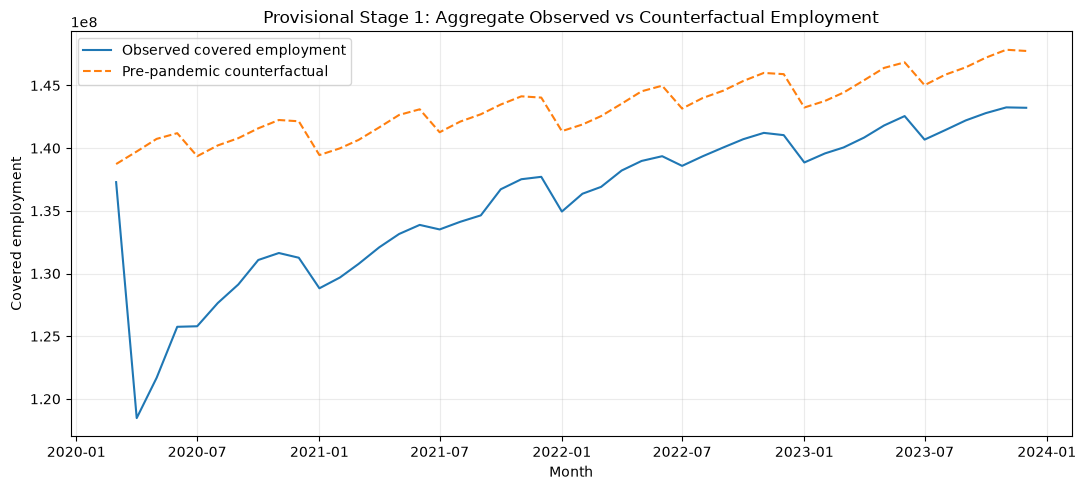

Gap distribution (%):


count    42596.000000
mean        -3.621894
std          5.001143
min        -39.642771
1%         -18.497484
5%         -11.412455
50%         -3.555867
95%          3.721614
99%          9.128798
max         42.700770
Name: gap_pct, dtype: float64

In [14]:
observed = panel.loc[panel.date >= pd.Timestamp('2020-03-01'), ['cbsa_code','date','employment','cbsa_type']]
gaps = forecast.merge(observed, on=['cbsa_code','date'], how='left', validate='one_to_one')
assert gaps.employment.notna().all()
gaps['gap_pct'] = 100 * (gaps.employment - gaps.counterfactual_employment) / gaps.counterfactual_employment
gaps['shortfall_pct'] = (-gaps.gap_pct).clip(lower=0)
gaps.to_csv(PROCESSED / 'stage1_cbsa_observed_vs_counterfactual_2020_2023.csv', index=False)

aggregate = gaps.groupby('date', as_index=False)[['employment','counterfactual_employment']].sum()
fig, ax = plt.subplots(figsize=(11,5))
ax.plot(aggregate.date, aggregate.employment, label='Observed covered employment')
ax.plot(aggregate.date, aggregate.counterfactual_employment, label='Pre-pandemic counterfactual', linestyle='--')
ax.set(title='Provisional Stage 1: Aggregate Observed vs Counterfactual Employment',
       xlabel='Month', ylabel='Covered employment')
ax.legend(); ax.grid(alpha=.25); fig.tight_layout()
fig.savefig(OUTPUT / 'figure_stage1_aggregate_observed_counterfactual.png', dpi=300, bbox_inches='tight')
plt.show()

print('Gap distribution (%):')
display(gaps.gap_pct.describe(percentiles=[.01,.05,.5,.95,.99]))


## 9. Sensitivity audit: unusually volatile CBSA 48780
The large 2010–2014 employment expansion in Williams County, North Dakota (CBSA 48780) is currently retained.

In [15]:
target_code = '48780'
if target_code in set(forecast.cbsa_code):
    display(selected.loc[selected.cbsa_code.eq(target_code)])
    display(cv_aggregate.loc[cv_aggregate.cbsa_code.eq(target_code)].sort_values('mean_normalized_mae'))
    display(gaps.loc[gaps.cbsa_code.eq(target_code), ['date','employment','counterfactual_employment','gap_pct']].head(12))
    no_target = gaps.loc[~gaps.cbsa_code.eq(target_code)].groupby('date')[['employment','counterfactual_employment']].sum()
    no_target['gap_pct'] = 100*(no_target.employment-no_target.counterfactual_employment)/no_target.counterfactual_employment
    no_target.to_csv(OUTPUT / 'stage1_aggregate_excluding_cbsa_48780.csv')
else:
    print('CBSA 48780 not in current run (perhaps MAX_CBSAS was set).')


,cbsa_code,model,origins,mean_mae,mean_rmse,mean_normalized_mae
903,48780,seasonal_drift,3,945.049603,1271.569703,0.030996


,cbsa_code,model,origins,mean_mae,mean_rmse,mean_normalized_mae
4517,48780,seasonal_drift,3,945.049603,1271.569703,0.030996
4516,48780,sarima_auto,3,1267.475343,1424.222520,0.041488
4515,48780,ets_auto,3,1355.144095,1527.120126,0.044412
4518,48780,seasonal_naive,3,1636.777778,1770.544282,0.053782
4519,48780,trend_seasonal,3,9445.245251,9481.168927,0.309675


,date,employment,counterfactual_employment,gap_pct
41538,2020-03-01,28775.0,30219.090909,-4.778737
41539,2020-04-01,24555.0,30478.090909,-19.433930
41540,2020-05-01,23056.0,31096.090909,-25.855632
41541,2020-06-01,22878.0,31740.090909,-27.920811
41542,2020-07-01,22011.0,31648.090909,-30.450781
41543,2020-08-01,22305.0,32078.090909,-30.466560
41544,2020-09-01,22733.0,32078.090909,-29.132316
41545,2020-10-01,23156.0,31982.090909,-27.596979
41546,2020-11-01,22426.0,31243.090909,-28.220930
41547,2020-12-01,22142.0,30956.090909,-28.472881


## 10. Reproducibility manifest and methodological limitations

**Interpretation:** Stage 1 forecasts represent model-dependent hypothetical employment paths absent the pandemic. They cannot isolate pandemic causality from other contemporaneous shocks. Forecast uncertainty and sensitivity to the geographic vintage, model family, estimation window, and horizon must be assessed before drawing strong substantive conclusions. This notebook implements the **first baseline**, not the full robustness program.

**Validation limitation:** Rolling-origin 12-month backtests assess near-term predictive skill, not the full 46-month counterfactual horizon. Longer-horizon pre-pandemic pseudo-out-of-sample validation using earlier cutoffs is a recommended extension. The seasonal-drift specification uses an extrapolated annual level change and may become implausible over long horizons; check resulting forecasts before using them in resilience metrics.

In [16]:
manifest = {
    'input_file': str(source_file.relative_to(ROOT)),
    'panel_start': str(panel.date.min().date()),
    'panel_end': str(panel.date.max().date()),
    'training_cutoff': TRAIN_END,
    'forecast_end': FORECAST_END,
    'forecast_months': len(forecast_dates),
    'validation_origins': VALIDATION_ORIGINS,
    'validation_horizon_months': VALIDATION_HORIZON,
    'model_candidates': list(MODELS),
    'selection_metric': 'mean normalized MAE across 12-month pre-pandemic validation windows',
    'cbsa_count': len(cbsa_ids),
    'random_seed': SEED,
    'parallel_workers': N_JOBS,
    'parallel_backend': PARALLEL_BACKEND,
    'python': platform.python_version(),
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'geography': 'provisional 2023 CBSA delineation, 926 fully observed CBSAs',
    'notes': 'Pandemic observations excluded from Stage 1 fitting and model selection.'
}
(OUTPUT / 'stage1_run_manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
print('Saved manifest:', OUTPUT / 'stage1_run_manifest.json')
print('Completed Stage 1 baseline notebook.')


Saved manifest: c:\Users\adamt\OneDrive\Documents\Directed Practicum\regional-labor-resilience\output\stage1_run_manifest.json
Completed Stage 1 baseline notebook.
